# Smart Waste Sorter · 01 Convolutional Neural Networks

**Week 1 milestone.** Build the baseline every later approach is compared against:

- **Part A:** a small CNN trained from scratch at 128 × 128
- **Part B:** a ResNet-18 pretrained on ImageNet, fine-tuned at 224 × 224 (transfer learning)
- **Part C:** error analysis

Fill in every cell marked **TODO**; they raise `NotImplementedError` until you do.
Runtime → Change runtime type → **T4 GPU**. Run `00_setup_and_data` first.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="NIYOMUGENGA MARIE CLAIRE")

import torch, torch.nn as nn
import matplotlib.pyplot as plt

Copying data from Drive to the local disk (once per session)...
Team: NIYOMUGENGA MARIE CLAIRE | root: ./waste_sorter | device: cpu | smoke test: False


## Part A · A small CNN from scratch

**TODO 1.** Build `SmallCNN`: three blocks of `Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2)`
with 32, 64 and 128 filters, then `AdaptiveAvgPool2d(1)`, `Flatten`, `Dropout(0.3)` and a `Linear` layer
with one output per class.

Before you run it, work out by hand the shape after each block for a 3 × 128 × 128 input
(lecture: ⌊(W − K + 2P) / S⌋ + 1). Write your answer in your findings note.

### TODO 1: feature-map shapes (calculated by hand)

Formula: output = ⌊(W − K + 2P) / S⌋ + 1

- Conv2d: K = 3, P = 1, S = 1 (size stays the same, channels change)
- MaxPool2d(2): K = 2, P = 0, S = 2 (size is halved)
- Input: 3 × 128 × 128

| Block | Conv calculation | After conv | After MaxPool calculation | After pool |
|---|---|---|---|---|
| 1 (32 filters) | (128 − 3 + 2)/1 + 1 = 128 | 32 × 128 × 128 | (128 − 2 + 0)/2 + 1 = 64 | **32 × 64 × 64** |
| 2 (64 filters) | (64 − 3 + 2)/1 + 1 = 64 | 64 × 64 × 64 | (64 − 2 + 0)/2 + 1 = 32 | **64 × 32 × 32** |
| 3 (128 filters) | (32 − 3 + 2)/1 + 1 = 32 | 128 × 32 × 32 | (32 − 2 + 0)/2 + 1 = 16 | **128 × 16 × 16** |

After the three blocks:
- `AdaptiveAvgPool2d(1)` → 128 × 1 × 1
- `Flatten` → 128 values
- `Dropout(0.3)` → still 128 values (dropout doesn't change the shape)
- `Linear(128, 6)` → 6 outputs, one per class

**Expected printed feature-map shape:** `(2, 128, 16, 16)` (the 2 is the batch size), and the output shape is `(2, 6)`.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=len(ws.CLASSES)):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

model = SmallCNN()
x = torch.randn(2, 3, 128, 128)
print("feature map shape:", tuple(model.features(x).shape), "| output:", tuple(model(x).shape))
print(f"parameters: {ws.count_params(model):.2f} M")

feature map shape: (2, 128, 16, 16) | output: (2, 6)
parameters: 0.09 M


epoch 1/15  train loss 1.372  val acc 0.488  val macro-F1 0.416
epoch 2/15  train loss 1.197  val acc 0.559  val macro-F1 0.475
epoch 3/15  train loss 1.143  val acc 0.512  val macro-F1 0.423
epoch 4/15  train loss 1.075  val acc 0.599  val macro-F1 0.516
epoch 5/15  train loss 1.054  val acc 0.615  val macro-F1 0.520
epoch 6/15  train loss 0.989  val acc 0.567  val macro-F1 0.513
epoch 7/15  train loss 0.990  val acc 0.528  val macro-F1 0.422
epoch 8/15  train loss 0.951  val acc 0.588  val macro-F1 0.539
epoch 9/15  train loss 0.929  val acc 0.644  val macro-F1 0.580
epoch 10/15  train loss 0.915  val acc 0.686  val macro-F1 0.608
epoch 11/15  train loss 0.894  val acc 0.707  val macro-F1 0.647
epoch 12/15  train loss 0.867  val acc 0.702  val macro-F1 0.660
epoch 13/15  train loss 0.857  val acc 0.694  val macro-F1 0.635
epoch 14/15  train loss 0.853  val acc 0.712  val macro-F1 0.655
epoch 15/15  train loss 0.835  val acc 0.712  val macro-F1 0.655
test accuracy 0.686 | macro-F1 0.6

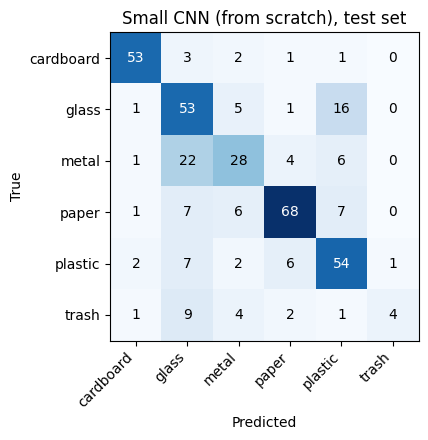

Logged: {'method': 'CNN from scratch', 'test_accuracy': '0.6860', 'test_macro_f1': '0.6332', 'trash_f1': '0.3077', 'local_accuracy': '0.2667'}


In [ ]:
train_dl, val_dl, test_dl = ws.make_loaders(img_size=128, batch_size=32, augment=False)
minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(15), lr=1e-3)

test = ws.evaluate(model, test_dl)
local_dl = ws.local_test_loader(128)
local = ws.evaluate(model, local_dl) if local_dl else None
print(f"test accuracy {test['accuracy']:.3f} | macro-F1 {test['macro_f1']:.3f} | trash F1 {test['trash_f1']:.3f}")
ws.plot_confusion(test, "Small CNN (from scratch), test set")
ws.log_result(1, "CNN from scratch", test, local, params_millions=ws.count_params(model), train_minutes=minutes,
              notes="SmallCNN 128px 15 epochs")

### Part A results: SmallCNN from scratch (128 px, 15 epochs)

- Test accuracy 0.686, macro-F1 0.633, trash F1 0.308; local-photo accuracy 0.267.
- Most confused classes: **metal → glass** (22 of 61 metal images) and **glass → plastic** (16 of 76). These classes are shiny or transparent objects with similar reflections and backgrounds, and a small CNN trained from scratch on ~1,800 images has little data to separate them.
- Trash is the weakest class (4 of 21 correct, F1 0.308). It is the smallest class (96 training images) and contains very different objects, so it has no consistent appearance.
- Validation F1 was still improving at epoch 15, so the model is under-trained.
- Accuracy drops from 0.686 on TrashNet to 0.267 on my local photos, because they differ in background, lighting and image quality.

## Part B · Transfer learning with ResNet-18

**TODO 2.** Load `torchvision.models.resnet18` with ImageNet weights (`weights` is set for you) and replace
its final layer `fc` with a new `nn.Linear` that has one output per class.
Fine-tune the whole network with a small learning rate.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


epoch 1/5  train loss 0.628  val acc 0.860  val macro-F1 0.857
epoch 2/5  train loss 0.156  val acc 0.884  val macro-F1 0.880
epoch 3/5  train loss 0.051  val acc 0.897  val macro-F1 0.892
epoch 4/5  train loss 0.021  val acc 0.918  val macro-F1 0.909
epoch 5/5  train loss 0.011  val acc 0.921  val macro-F1 0.910
test accuracy 0.937 | macro-F1 0.926 | trash F1 0.850


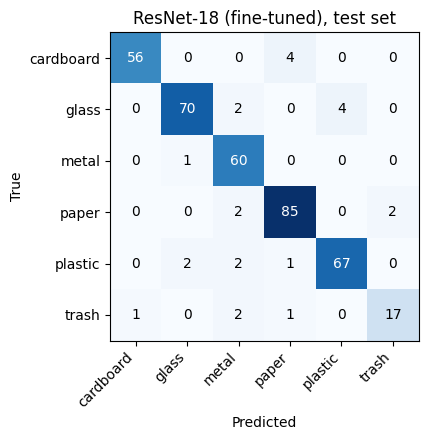

Logged: {'method': 'ResNet-18 fine-tuned', 'test_accuracy': '0.9367', 'test_macro_f1': '0.9264', 'trash_f1': '0.8500', 'local_accuracy': '0.2833'}


In [ ]:
from torchvision.models import resnet18, ResNet18_Weights
weights = None if ws.SMOKE else ResNet18_Weights.DEFAULT

def make_resnet18():
    m = resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

ws.seed_everything()
resnet = make_resnet18()
train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, augment=False)
minutes = ws.train_classifier(resnet, train_dl, val_dl, n_epochs=ws.epochs(5), lr=3e-4)

test_r = ws.evaluate(resnet, test_dl)
local_dl = ws.local_test_loader(224)
local_r = ws.evaluate(resnet, local_dl) if local_dl else None
print(f"test accuracy {test_r['accuracy']:.3f} | macro-F1 {test_r['macro_f1']:.3f} | trash F1 {test_r['trash_f1']:.3f}")
ws.plot_confusion(test_r, "ResNet-18 (fine-tuned), test set")
ws.log_result(1, "ResNet-18 fine-tuned", test_r, local_r, params_millions=ws.count_params(resnet),
              train_minutes=minutes, notes="ImageNet weights 224px 5 epochs")
torch.save(resnet.state_dict(), os.path.join(ws.ROOT, "checkpoints", "resnet18_week1.pt"))

### Part B results: ResNet-18 fine-tuned (224 px, 5 epochs)

- Test accuracy 0.937, macro-F1 0.926, trash F1 0.850; local-photo accuracy 0.283.
- Compared with the SmallCNN: accuracy +0.251, macro-F1 +0.293, trash F1 +0.542, in 5 epochs instead of 15.
- Pretraining helps because ResNet-18 already learned general visual features (edges, textures, shapes, reflections) from 1.2 million ImageNet images. With only 1,766 training images, the SmallCNN had to learn these from scratch. ResNet-18 only had to adapt them to six waste classes.
- The metal/glass/plastic confusion almost disappeared (metal → glass: 22 errors → 1), and trash F1 rose from 0.308 to 0.850.
- The local-photo accuracy barely improved (0.267 → 0.283). The model fits the TrashNet style (plain backgrounds, single objects) very well, but my local photos differ, so pretraining alone does not solve this domain shift.

## Part C · Error analysis

**TODO 3.** Find the test images the ResNet got wrong and show up to 12 of them, each titled
`true → predicted`. Use `test_r["y_true"]`, `test_r["y_pred"]` and the `path` column of the test split.

24 wrong out of 379 test images


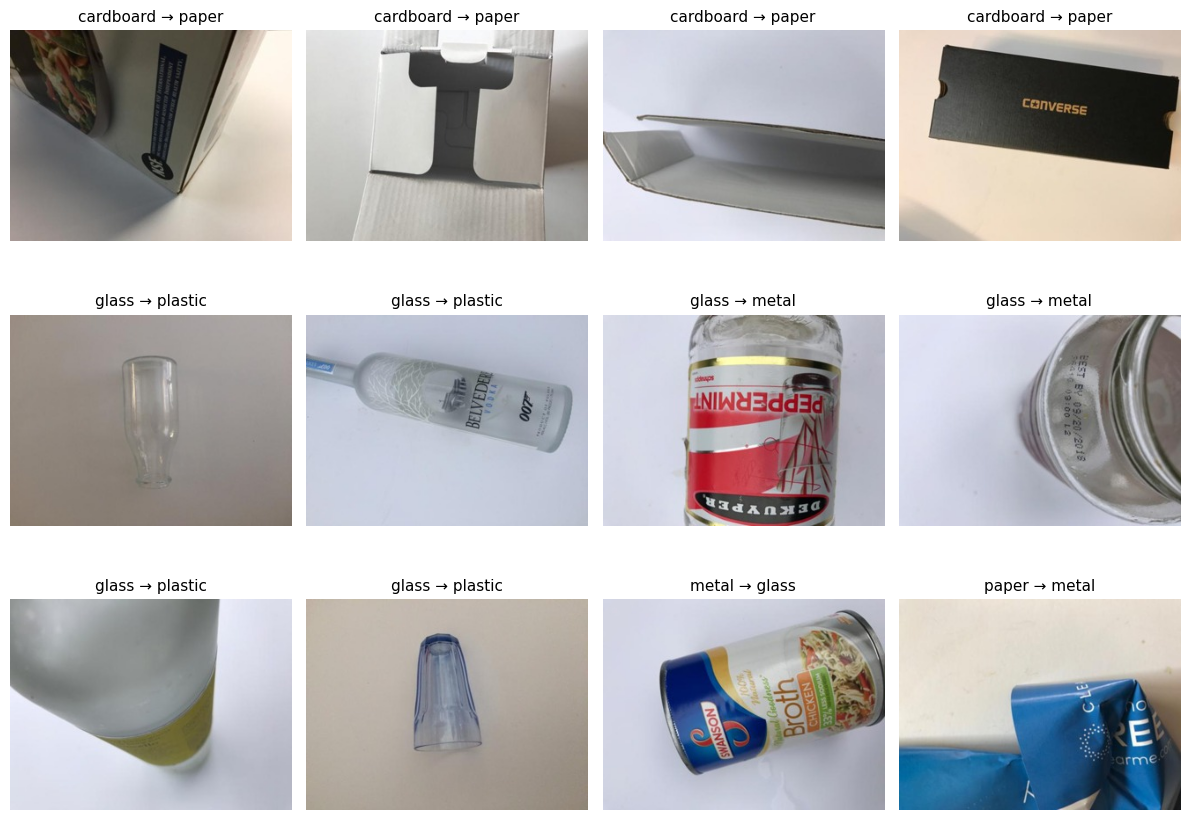

In [ ]:
from PIL import Image
import numpy as np
split = ws.load_split()
test_split = split[split.split == "test"]
test_paths = test_split.path.tolist()

y_true = np.array(test_r["y_true"])
y_pred = np.array(test_r["y_pred"])
# sanity check: the order of the test images matches the predictions
assert (y_true == test_split.label_id.values).all(), "order mismatch"

wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} wrong out of {len(y_true)} test images")

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong[:12]):
    ax.imshow(Image.open(test_paths[i]))
    ax.set_title(f"{ws.CLASSES[y_true[i]]} → {ws.CLASSES[y_pred[i]]}", fontsize=11)
plt.tight_layout()
plt.show()

### Part C: error analysis (ResNet-18, 24 of 379 test images wrong)

**Most confused classes:** cardboard → paper (4) and glass → plastic (4), followed by several pairs with 2 errors each (glass → metal, paper → metal, paper → trash, plastic → glass, plastic → metal, trash → metal).

**Why these errors happen (from the first 12 misclassified images):**
- *Cardboard → paper:* the boxes are smooth, plain white or black, with no visible corrugated texture, so they look like paper.
- *Glass → plastic:* transparent or frosted bottles and cups have soft reflections that look like clear plastic. One blue-tinted cup could honestly be plastic.
- *Glass → metal and metal → glass:* large printed labels (the red label on the Peppermint bottle, the paper label on the Swanson can) and close-ups hide the real material, so the model relies on shape and colour.
- Some labels are debatable, for example the crumpled blue packaging labelled paper.

The model recognises appearance (colour, texture, shape), not the material itself. It fails when that appearance is ambiguous, covered by a label, or cropped.

## Stretch · Data augmentation
Set `RUN_STRETCH = True` to fine-tune ResNet-18 again with random crops, flips, rotations and colour
jitter. Does it help on the TrashNet test set? On your local photos?

In [6]:
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.DEFAULT

def make_resnet18():
    m = resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

local_dl = ws.local_test_loader(224)
print("local photos loaded:", local_dl is not None)

RUN_STRETCH = True
if RUN_STRETCH:
    ws.seed_everything()
    resnet_aug = make_resnet18()
    tr_aug, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, augment=True)
    minutes = ws.train_classifier(resnet_aug, tr_aug, val_dl, n_epochs=ws.epochs(8), lr=3e-4)
    test_a = ws.evaluate(resnet_aug, test_dl)
    local_a = ws.evaluate(resnet_aug, local_dl) if local_dl else None
    print(f"test accuracy {test_a['accuracy']:.3f} | macro-F1 {test_a['macro_f1']:.3f} | trash F1 {test_a['trash_f1']:.3f}")
    ws.log_result(1, "ResNet-18 + augmentation", test_a, local_a, params_millions=ws.count_params(resnet_aug),
                  train_minutes=minutes, notes="augment 8 epochs")

local photos loaded: True
epoch 1/8  train loss 0.750  val acc 0.773  val macro-F1 0.762
epoch 2/8  train loss 0.401  val acc 0.831  val macro-F1 0.798
epoch 3/8  train loss 0.304  val acc 0.876  val macro-F1 0.858
epoch 4/8  train loss 0.177  val acc 0.876  val macro-F1 0.869
epoch 5/8  train loss 0.116  val acc 0.905  val macro-F1 0.899
epoch 6/8  train loss 0.060  val acc 0.923  val macro-F1 0.917
epoch 7/8  train loss 0.040  val acc 0.916  val macro-F1 0.909
epoch 8/8  train loss 0.030  val acc 0.913  val macro-F1 0.908
test accuracy 0.923 | macro-F1 0.915 | trash F1 0.857
Logged: {'method': 'ResNet-18 + augmentation', 'test_accuracy': '0.9235', 'test_macro_f1': '0.9154', 'trash_f1': '0.8571', 'local_accuracy': '0.3667'}


### Stretch: data augmentation (ResNet-18, 224 px, 8 epochs)

| | Test acc | Macro-F1 | Trash F1 | Local acc |
|---|---|---|---|---|
| ResNet-18 | 0.937 | 0.926 | 0.850 | 0.283 |
| ResNet-18 + augmentation | 0.923 | 0.915 | 0.857 | 0.367 |

Augmentation did not help on the TrashNet test set (accuracy 0.937 → 0.923, about 5 images out of 379, within noise), but it improved local-photo accuracy from 0.283 to 0.367 (22 of 60 photos instead of 17). Random crops, flips, rotations and colour changes make the model less tied to TrashNet's fixed look. The gain on my photos is small and uncertain because there are only 60 of them, and the comparison is not fully controlled: the augmented run used 8 epochs on a CPU, while the baseline used 5 epochs on a GPU (the Colab GPU quota ran out).

**3. How far does accuracy drop on my local photos?**
SmallCNN 0.686 → 0.267, ResNet-18 0.937 → 0.283, ResNet-18 + augmentation 0.923 → 0.367. The drop is very large. TrashNet images show one object on a plain light background with consistent lighting, and the models fit that style well. [Add what is different about your photos: background, lighting, number of objects, angle, camera quality.] This is a domain shift between the training data and real-world photos. Augmentation reduces it a little, but more varied training data would likely be needed to close the gap.

## Questions for your week-1 findings note
1. Which two classes are confused most, and why might that be?
2. How much did pretraining help (accuracy, macro-F1, trash F1)? Why does it help so much on a small dataset?
3. How far does accuracy drop on your local photos? What is different about them?
4. Write the feature-map shapes you calculated for TODO 1 and check them against the printed shape.

## Week 1 findings note

**1. Which two classes are confused most, and why?**
For the SmallCNN, metal → glass (22 of 61 metal images) and glass → plastic (16 of 76). For ResNet-18, the most frequent errors are cardboard → paper (4) and glass → plastic (4). These materials look alike: plain white or black boxes lack visible corrugation and look like paper, and transparent or frosted glass looks like clear plastic. Printed labels and close-ups hide the real material (for example the Swanson can and the Peppermint bottle), so the model relies on colour, shape and texture rather than the material itself.

**2. How much did pretraining help? Why does it help so much on a small dataset?**

| Metric | SmallCNN | ResNet-18 |
|---|---|---|
| Test accuracy | 0.686 | 0.937 |
| Macro-F1 | 0.633 | 0.926 |
| Trash F1 | 0.308 | 0.850 |

Pretraining gave +0.251 accuracy, +0.293 macro-F1 and +0.542 trash F1, in 5 epochs instead of 15. ResNet-18 already learned general features (edges, textures, shapes, reflections) from 1.2 million ImageNet images, so with only 1,766 training images it only had to adapt them to six waste classes. The SmallCNN had to learn everything from scratch, and its validation F1 was still rising at epoch 15, so it was under-trained.

**3. How far does accuracy drop on my local photos? What is different about them?**
SmallCNN: 0.686 → 0.267. ResNet-18: 0.937 → 0.283. Pretraining barely helped on my own photos. The TrashNet images show a single object on a plain, light background, and the models fit that style very well (ResNet training loss reached 0.011). [Add what is different about your photos: background, lighting, number of objects, framing, camera quality.] This is a domain shift between the training data and real-world photos. “Data augmentation raised local accuracy to 0.367 (see the stretch results above ), a small gain.

**4. Feature-map shapes for TODO 1**
Calculated by hand: 32 × 64 × 64 → 64 × 32 × 32 → 128 × 16 × 16. The printed shape was `(2, 128, 16, 16)`, which matches (the 2 is the batch size). Parameters: 0.09 M (94,470).